<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/01-segmentacao-em-imagem.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 1. Segmentação em uma imagem

Uma caixa diz onde o objeto está, mais ou menos. Num quarto de hospital, o retângulo do leito leva junto o chão, a cortina e um pedaço da parede. A segmentação devolve a forma: uma máscara com os pixels que são o leito.

O modelo é o `yolov8n-seg`, a versão nano de segmentação. Tem uns 7 MB, roda sem GPU e conhece as 80 classes do COCO. Leito e cadeira estão nessa lista. Uma lesão, um órgão ou uma trinca no concreto, não. A caixa continua vindo. Junto com ela, vem a máscara.

> No Colab: **Ambiente de execução → Executar tudo**. GPU é opcional aqui.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Carregar o modelo e a foto

Na primeira chamada, `YOLO("yolov8n-seg.pt")` baixa os pesos. A foto é um quarto de hospital, com dois leitos e cadeiras.

In [3]:
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n-seg.pt")
imagem = baixar("https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/enfermaria.jpg", "enfermaria.jpg")

enfermaria.jpg: 0.2 MB


## Rodar a segmentação

`model(imagem)` devolve um resultado por foto. `plot()` desenha a caixa e pinta a máscara. `mascaras_originais` estica cada máscara de volta ao tamanho da foto, porque a rede responde numa grade menor.

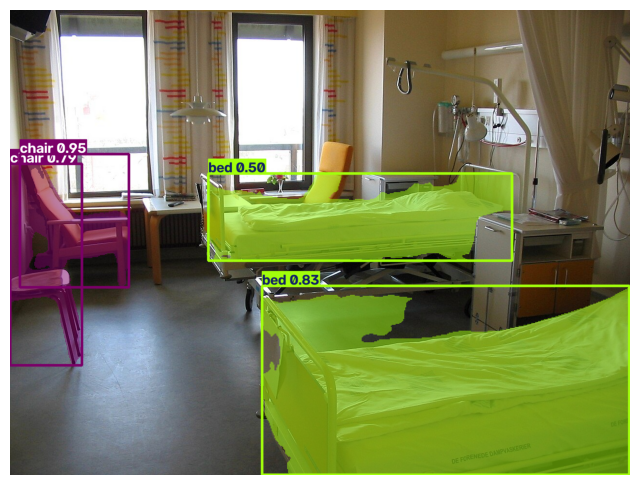

4 máscaras, foto 960x1280


In [4]:
resultado = model(imagem, verbose=False)[0]
mascaras = mascaras_originais(resultado)

plt.figure(figsize=(8, 10))
plt.imshow(resultado.plot()[:, :, ::-1])  # BGR -> RGB
plt.axis("off")
plt.show()
print(f"{len(mascaras)} máscaras, foto {mascaras.shape[1]}x{mascaras.shape[2]}")
assert len(mascaras) > 0

## Ler a máscara como dado

Cada máscara é uma grade de verdadeiro ou falso, na mesma ordem das caixas. Somar os `True` dá a área em pixels. A confiança continua na caixa.

In [5]:
areas = mascaras.sum(axis=(1, 2))
for i, caixa in enumerate(resultado.boxes):
    classe = model.names[int(caixa.cls)]
    conf = float(caixa.conf)
    print(f"{classe:10s} {conf:5.0%}  {int(areas[i]):7d} pixels")

chair        95%    25140 pixels
bed          83%   246516 pixels
chair        79%    23680 pixels
bed          50%    84912 pixels


## A caixa é maior que o objeto

A área da máscara dividida pela área da caixa mostra quanto do retângulo é objeto de verdade. No leito, uma parte da caixa é chão e cortina.

In [6]:
for i, caixa in enumerate(resultado.boxes):
    x1, y1, x2, y2 = caixa.xyxy[0].tolist()
    area_caixa = (x2 - x1) * (y2 - y1)
    fracao = float(areas[i]) / area_caixa
    print(f"{model.names[int(caixa.cls)]:10s}  máscara/caixa = {fracao:.0%}")

chair       máscara/caixa = 41%
bed         máscara/caixa = 83%
chair       máscara/caixa = 38%
bed         máscara/caixa = 75%


## Exercícios

Seis perguntas sobre o que acabou de rodar. Escreva a resposta na variável `resposta` e rode a célula: a função `conferir` diz na hora se está certo. Se travar, abra **Ver solução**.

Rode antes a célula de preparação abaixo. Ela só carrega as verificações.

In [7]:
# @title Preparação dos exercícios (rode, não precisa ler)
import numpy as np

_cls = resultado.boxes.cls.int().tolist()
_conf = resultado.boxes.conf.tolist()
_xyxy = resultado.boxes.xyxy.tolist()


def _indices(nome):
    return [i for i, c in enumerate(_cls) if model.names[c] == nome]


def _fracao_leitos():
    uniao = np.any(mascaras[_indices("bed")], axis=0)
    return float(uniao.mean())


def _n_leitos():
    indice = [i for i, nome in model.names.items() if nome == "bed"][0]
    r = model(imagem, classes=[indice], verbose=False)[0]
    return 0 if r.masks is None else len(r.masks)


VERIFICAR = {
    1: lambda r: int(r) == len(mascaras),
    2: lambda r: set(r) == {model.names[c] for c in _cls},
    3: lambda r: abs(float(r) - max(_conf)) < 1e-3,
    4: lambda r: int(r) == int(mascaras.sum(axis=(1, 2)).max()),
    5: lambda r: int(r) == _n_leitos(),
    6: lambda r: abs(float(r) - _fracao_leitos()) < 1e-3,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Quantas máscaras

Quantas máscaras o modelo devolveu em `mascaras`?

<details>
<summary>Ver solução</summary>

```python
resposta = len(mascaras)
```

</details>

In [8]:
# Dica: len(mascaras) é o número de objetos segmentados.
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


### Exercício 2. Classes com máscara

Monte um conjunto (`set`) com os **nomes** das classes que ganharam máscara.

<details>
<summary>Ver solução</summary>

```python
resposta = {model.names[int(c)] for c in resultado.boxes.cls}
```

</details>

In [9]:
# Dica: model.names traduz o índice que está em resultado.boxes.cls.
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


### Exercício 3. A máscara mais segura

Qual é a maior confiança entre as máscaras? Responda com um número entre 0 e 1.

<details>
<summary>Ver solução</summary>

```python
resposta = float(resultado.boxes.conf.max())
```

</details>

In [10]:
# Dica: A confiança fica em resultado.boxes.conf, na mesma ordem das máscaras.
resposta = None

conferir(3, resposta)

Exercício 3: ainda sem resposta.


### Exercício 4. Área da maior máscara

Quantos pixels tem a maior máscara? Cada `True` em `mascaras` é um pixel do objeto.

<details>
<summary>Ver solução</summary>

```python
resposta = int(mascaras.sum(axis=(1, 2)).max())
```

</details>

In [11]:
# Dica: mascaras.sum(axis=(1, 2)) soma a área de cada objeto.
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


### Exercício 5. Só os leitos

Rode o modelo de novo na mesma foto, pedindo só a classe `bed`. Quantas máscaras vieram? O índice da classe está em `model.names`.

<details>
<summary>Ver solução</summary>

```python
indice = [i for i, nome in model.names.items() if nome == "bed"][0]
r = model(imagem, classes=[indice], verbose=False)[0]
resposta = 0 if r.masks is None else len(r.masks)
```

</details>

In [12]:
# Dica: Ache o índice de bed e passe em classes=[indice]. Se masks vier vazio, a conta é zero.
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


### Exercício 6. Os leitos na foto

Que fração da foto os leitos cobrem, somando as máscaras de `bed`? Responda com um número entre 0 e 1.

<details>
<summary>Ver solução</summary>

```python
idx = [i for i, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "bed"]
resposta = float(np.any(mascaras[idx], axis=0).mean())
```

</details>

In [13]:
# Dica: np.any junta máscaras, e .mean() num array booleano é a fração de True.
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


In [14]:
placar()

0 de 6 exercícios certos.


## O que fica

A máscara é um array. Dá para contar pixel, recortar e medir. O que ela ainda não faz sozinha é lembrar do mesmo objeto no quadro seguinte: cada foto é uma conta nova.

Para experimentar com uma foto sua, troque a URL em `baixar(...)` ou suba o arquivo pelo painel lateral do Colab.